## Task Description:

## You are required to:

1. ***Build and train a GAN model using TensorFlow 2.x (Keras API) consisting of***:

- Generator Network: Takes a random noise vector (e.g., 100-dimensional) and outputs a 28×28 grayscale image. 
- Discriminator Network: Classifies input images (real or generated) as true (1) or fake (0).

**Dataset: Use the MNIST dataset available in TensorFlow:**


(x_train, \_), (\_, \_) = tf.keras.datasets.mnist.load_data()

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers
import os
import time

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Libraries imported successfully!")


TensorFlow Version: 2.21.0
NumPy Version: 1.26.4
Libraries imported successfully!


In [2]:

# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Display dataset information
print("MNIST Dataset Loaded Successfully!")
print("Training images shape:", x_train.shape)
print("Total training images:", len(x_train))
print("Image height:", x_train.shape[1])
print("Image width:", x_train.shape[2])


MNIST Dataset Loaded Successfully!
Training images shape: (60000, 28, 28)
Total training images: 60000
Image height: 28
Image width: 28


In [3]:

# Normalize images to the range [-1, 1]
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images to include the channel dimension
x_train = np.expand_dims(x_train, axis=-1)

# Create TensorFlow dataset
BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)

# Display preprocessing details
print("Preprocessing completed successfully!")
print("Dataset shape:", x_train.shape)
print("Data type:", x_train.dtype)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Batch size:", BATCH_SIZE)


Preprocessing completed successfully!
Dataset shape: (60000, 28, 28, 1)
Data type: float32
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Batch size: 256


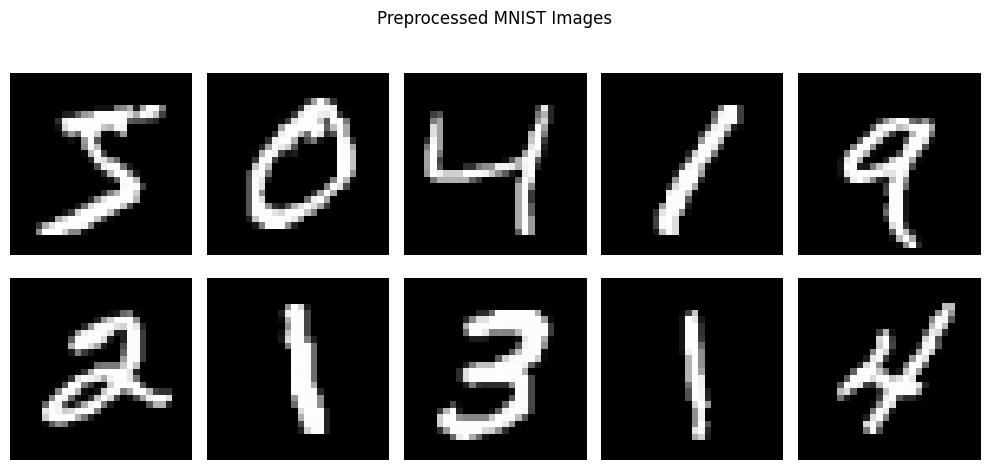

In [4]:

# Display preprocessed MNIST images

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.suptitle("Preprocessed MNIST Images")
plt.tight_layout()
plt.show()


In [6]:

# Generator Network

def build_generator():

    model = tf.keras.Sequential([
        layers.Dense(256, input_dim=100),
        layers.LeakyReLU(negative_slope=0.2),
        layers.BatchNormalization(),

        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.BatchNormalization(),

        layers.Dense(1024),
        layers.LeakyReLU(negative_slope=0.2),
        layers.BatchNormalization(),

        layers.Dense(28 * 28, activation='tanh'),

        layers.Reshape((28, 28, 1))
    ])

    return model


# Create Generator
generator = build_generator()

# Display Generator architecture
generator.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,493,520 (5.70 MB)

 Trainable params: 1,489,936 (5.68 MB)

 Non-trainable params: 3,584 (14.00 KB)

In [8]:

# Discriminator Network

def build_discriminator():

    model = tf.keras.Sequential([
        layers.Flatten(input_shape=(28, 28, 1)),

        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Dense(1, activation='sigmoid')
    ])

    return model


# Create Discriminator
discriminator = build_discriminator()

# Display Discriminator architecture
discriminator.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Generated image shape: (1, 28, 28, 1)
Discriminator prediction: [[0.43644765]]


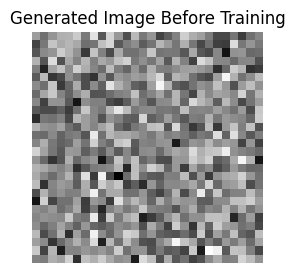

In [9]:

# Generate random noise
noise = tf.random.normal([1, 100])

# Generate a fake image
generated_image = generator(noise, training=False)

# Pass generated image to Discriminator
prediction = discriminator(generated_image, training=False)

print("Generated image shape:", generated_image.shape)
print("Discriminator prediction:", prediction.numpy())

# Display generated image
plt.figure(figsize=(3, 3))
plt.imshow(generated_image[0, :, :, 0], cmap='gray')
plt.title("Generated Image Before Training")
plt.axis('off')
plt.show()


In [10]:

# Define loss function
cross_entropy = tf.keras.losses.BinaryCrossentropy()

# Generator loss
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

# Discriminator loss
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss


# Define optimizers
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)

print("Loss functions and optimizers configured successfully!")


Loss functions and optimizers configured successfully!


In [11]:

# Set training parameters
EPOCHS = 50
noise_dim = 100
num_examples_to_generate = 16

# Fixed random noise for generating images
seed = tf.random.normal([num_examples_to_generate, noise_dim])

# Store loss values
generator_losses = []
discriminator_losses = []

# Training function
@tf.function
def train_step(images):

    batch_size = tf.shape(images)[0]

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Function to generate and save images
def generate_and_save_images(model, epoch, test_input):

    predictions = model(test_input, training=False)

    fig = plt.figure(figsize=(4, 4))

    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap='gray')
        plt.axis('off')

    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.savefig(f"generated_epoch_{epoch}.png")
    plt.show()
    plt.close()


# Complete training loop
def train(dataset, epochs):

    for epoch in range(epochs):

        start = time.time()

        total_gen_loss = 0
        total_disc_loss = 0
        batches = 0

        for image_batch in dataset:

            gen_loss, disc_loss = train_step(image_batch)

            total_gen_loss += gen_loss
            total_disc_loss += disc_loss
            batches += 1

        avg_gen_loss = (total_gen_loss / batches).numpy()
        avg_disc_loss = (total_disc_loss / batches).numpy()

        generator_losses.append(avg_gen_loss)
        discriminator_losses.append(avg_disc_loss)

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Generator Loss: {avg_gen_loss:.4f}, "
            f"Discriminator Loss: {avg_disc_loss:.4f}, "
            f"Time: {time.time() - start:.2f} sec"
        )

        if (epoch + 1) % 10 == 0:
            generate_and_save_images(generator, epoch + 1, seed)


print("GAN training functions implemented successfully!")


GAN training functions implemented successfully!


GAN Training Started...
Epoch 1/50, Generator Loss: 3.4916, Discriminator Loss: 0.1162, Time: 24.33 sec
Epoch 2/50, Generator Loss: 5.6386, Discriminator Loss: 0.0593, Time: 14.91 sec
Epoch 3/50, Generator Loss: 6.5128, Discriminator Loss: 0.0975, Time: 13.80 sec
Epoch 4/50, Generator Loss: 6.8580, Discriminator Loss: 0.1051, Time: 13.13 sec
Epoch 5/50, Generator Loss: 7.3105, Discriminator Loss: 0.1054, Time: 12.96 sec
Epoch 6/50, Generator Loss: 7.8032, Discriminator Loss: 0.1031, Time: 11.57 sec
Epoch 7/50, Generator Loss: 7.7964, Discriminator Loss: 0.0955, Time: 14.38 sec
Epoch 8/50, Generator Loss: 7.4352, Discriminator Loss: 0.1294, Time: 11.07 sec
Epoch 9/50, Generator Loss: 8.0424, Discriminator Loss: 0.1548, Time: 20.55 sec
Epoch 10/50, Generator Loss: 6.4888, Discriminator Loss: 0.2039, Time: 10.90 sec


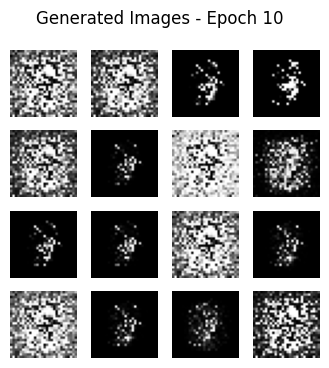

Epoch 11/50, Generator Loss: 7.2684, Discriminator Loss: 0.2076, Time: 15.43 sec
Epoch 12/50, Generator Loss: 5.6712, Discriminator Loss: 0.2301, Time: 11.46 sec
Epoch 13/50, Generator Loss: 5.3949, Discriminator Loss: 0.2708, Time: 13.50 sec
Epoch 14/50, Generator Loss: 5.0665, Discriminator Loss: 0.3041, Time: 12.89 sec
Epoch 15/50, Generator Loss: 4.4701, Discriminator Loss: 0.3904, Time: 13.05 sec
Epoch 16/50, Generator Loss: 4.0451, Discriminator Loss: 0.4456, Time: 12.50 sec
Epoch 17/50, Generator Loss: 3.7578, Discriminator Loss: 0.5313, Time: 11.33 sec
Epoch 18/50, Generator Loss: 2.8140, Discriminator Loss: 0.6878, Time: 14.20 sec
Epoch 19/50, Generator Loss: 2.3285, Discriminator Loss: 0.8005, Time: 12.15 sec
Epoch 20/50, Generator Loss: 1.9549, Discriminator Loss: 0.9062, Time: 14.40 sec


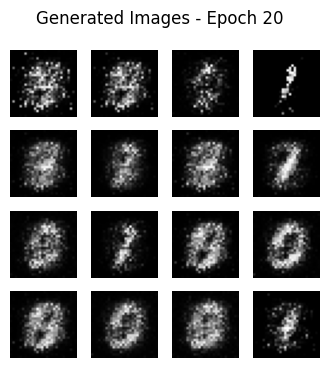

Epoch 21/50, Generator Loss: 1.8436, Discriminator Loss: 0.9267, Time: 13.81 sec
Epoch 22/50, Generator Loss: 1.7870, Discriminator Loss: 0.9249, Time: 15.05 sec
Epoch 23/50, Generator Loss: 1.5359, Discriminator Loss: 1.0136, Time: 11.87 sec
Epoch 24/50, Generator Loss: 1.5717, Discriminator Loss: 0.9539, Time: 11.90 sec
Epoch 25/50, Generator Loss: 1.6521, Discriminator Loss: 0.9538, Time: 13.28 sec
Epoch 26/50, Generator Loss: 1.6383, Discriminator Loss: 0.9943, Time: 10.72 sec
Epoch 27/50, Generator Loss: 1.6206, Discriminator Loss: 0.9797, Time: 13.86 sec
Epoch 28/50, Generator Loss: 1.6057, Discriminator Loss: 0.9910, Time: 11.31 sec
Epoch 29/50, Generator Loss: 1.4516, Discriminator Loss: 1.0601, Time: 12.87 sec
Epoch 30/50, Generator Loss: 1.4668, Discriminator Loss: 1.0504, Time: 12.83 sec


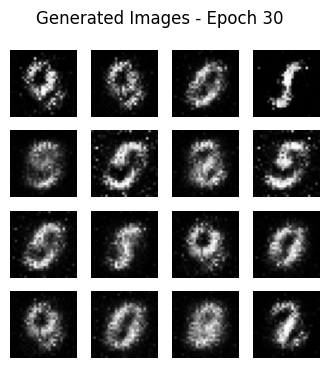

Epoch 31/50, Generator Loss: 1.5561, Discriminator Loss: 1.0215, Time: 11.74 sec
Epoch 32/50, Generator Loss: 1.6061, Discriminator Loss: 1.0253, Time: 14.06 sec
Epoch 33/50, Generator Loss: 1.5479, Discriminator Loss: 1.0260, Time: 11.89 sec
Epoch 34/50, Generator Loss: 1.6523, Discriminator Loss: 1.0155, Time: 14.71 sec
Epoch 35/50, Generator Loss: 1.5180, Discriminator Loss: 1.0526, Time: 11.96 sec
Epoch 36/50, Generator Loss: 1.5348, Discriminator Loss: 1.0596, Time: 13.26 sec
Epoch 37/50, Generator Loss: 1.4019, Discriminator Loss: 1.1192, Time: 13.38 sec
Epoch 38/50, Generator Loss: 1.4977, Discriminator Loss: 1.0713, Time: 12.93 sec
Epoch 39/50, Generator Loss: 1.4748, Discriminator Loss: 1.0920, Time: 14.12 sec
Epoch 40/50, Generator Loss: 1.4861, Discriminator Loss: 1.0536, Time: 11.98 sec


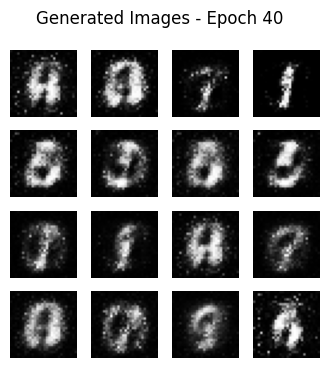

Epoch 41/50, Generator Loss: 1.4545, Discriminator Loss: 1.0574, Time: 15.32 sec
Epoch 42/50, Generator Loss: 1.3243, Discriminator Loss: 1.1663, Time: 11.70 sec
Epoch 43/50, Generator Loss: 1.2020, Discriminator Loss: 1.2005, Time: 14.29 sec
Epoch 44/50, Generator Loss: 1.1306, Discriminator Loss: 1.2318, Time: 12.59 sec
Epoch 45/50, Generator Loss: 1.1230, Discriminator Loss: 1.2092, Time: 14.08 sec
Epoch 46/50, Generator Loss: 1.2334, Discriminator Loss: 1.1778, Time: 12.98 sec
Epoch 47/50, Generator Loss: 1.2305, Discriminator Loss: 1.1697, Time: 13.64 sec
Epoch 48/50, Generator Loss: 1.1220, Discriminator Loss: 1.2273, Time: 13.42 sec
Epoch 49/50, Generator Loss: 1.1490, Discriminator Loss: 1.1848, Time: 12.18 sec
Epoch 50/50, Generator Loss: 1.2835, Discriminator Loss: 1.1427, Time: 14.49 sec


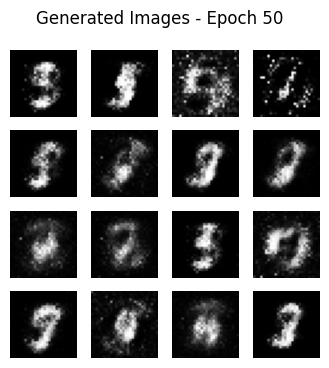

GAN Training Completed Successfully!


In [12]:

# Start GAN training

print("GAN Training Started...")

train(train_dataset, EPOCHS)

print("GAN Training Completed Successfully!")


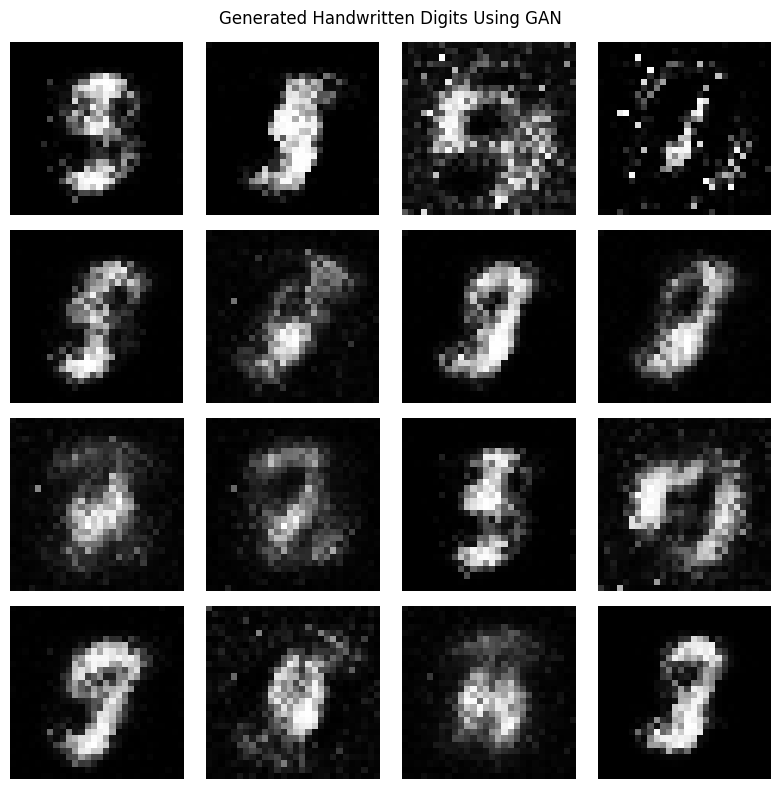

Final generated digit samples saved successfully!


In [13]:

# Generate final handwritten digit samples

predictions = generator(seed, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        predictions[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )
    plt.axis('off')

plt.suptitle("Generated Handwritten Digits Using GAN")
plt.tight_layout()

os.makedirs("output_images", exist_ok=True)

plt.savefig(
    "output_images/generated_digits_grid.png",
    dpi=150
)

plt.show()

print("Final generated digit samples saved successfully!")


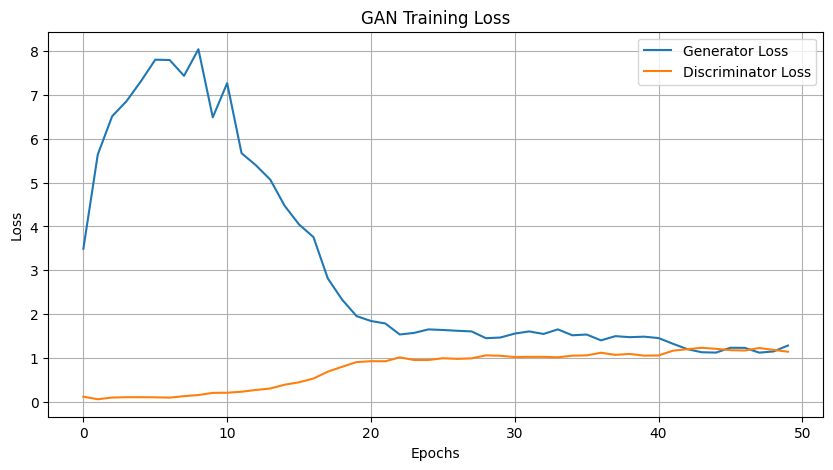

GAN loss graph saved successfully!


In [14]:

# Plot Generator and Discriminator Loss

plt.figure(figsize=(10, 5))

plt.plot(generator_losses, label='Generator Loss')
plt.plot(discriminator_losses, label='Discriminator Loss')

plt.title('GAN Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.savefig(
    'output_images/gan_training_loss.png',
    dpi=150
)

plt.show()

print("GAN loss graph saved successfully!")


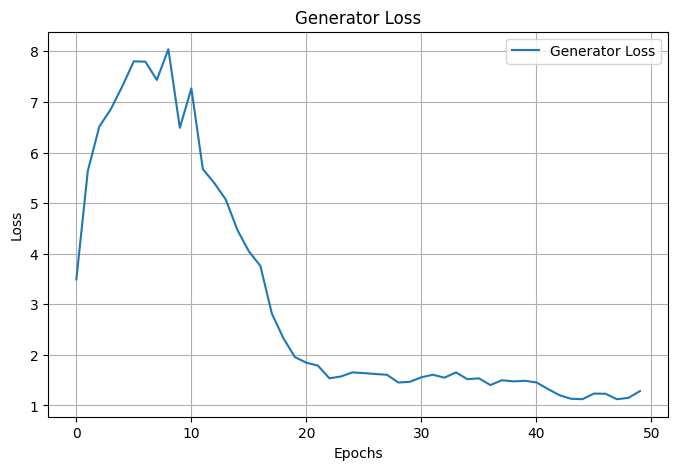

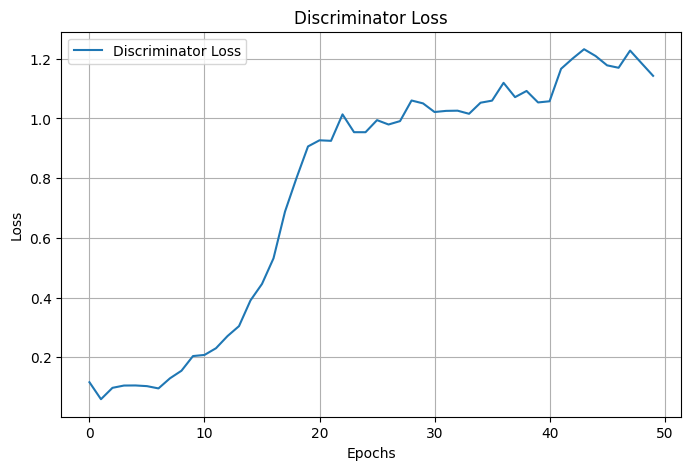

Individual loss graphs saved successfully!


In [15]:

# Generator Loss Graph

plt.figure(figsize=(8, 5))
plt.plot(generator_losses, label='Generator Loss')
plt.title('Generator Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig('output_images/generator_loss.png', dpi=150)
plt.show()


# Discriminator Loss Graph

plt.figure(figsize=(8, 5))
plt.plot(discriminator_losses, label='Discriminator Loss')
plt.title('Discriminator Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig('output_images/discriminator_loss.png', dpi=150)
plt.show()

print("Individual loss graphs saved successfully!")


In [16]:

print("Total training epochs:", len(generator_losses))
print("Generator loss values:", len(generator_losses))
print("Discriminator loss values:", len(discriminator_losses))

print("\nSaved output files:")

for folder in ["output_images"]:
    for file in os.listdir(folder):
        print(file)

print("\nTask 1 output verification completed!")


Total training epochs: 50
Generator loss values: 50
Discriminator loss values: 50

Saved output files:
discriminator_loss.png
gan_training_loss.png
generated_digits_grid.png
generator_loss.png

Task 1 output verification completed!


2. Normalize the data to the range [-1, 1] and reshape to (28, 28, 1).

In [17]:

# Task 2: Normalize and reshape MNIST dataset

# Normalize pixel values to [-1, 1]
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images to (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

# Verify preprocessing
print("Data normalization and reshaping completed!")
print("Dataset shape:", x_train.shape)
print("Data type:", x_train.dtype)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Data normalization and reshaping completed!
Dataset shape: (60000, 28, 28, 1, 1)
Data type: float32
Minimum pixel value: -1.0078431
Maximum pixel value: -0.99215686


In [19]:

# Reload original MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Convert to float32 and normalize only once
x_train = x_train.astype('float32')
x_train = (x_train - 127.5) / 127.5

# Reshape to (60000, 28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("Dataset preprocessing corrected successfully!")
print("Dataset shape:", x_train.shape)
print("Data type:", x_train.dtype)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Dataset preprocessing corrected successfully!
Dataset shape: (60000, 28, 28, 1)
Data type: float32
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [20]:

# Verify dataset
assert x_train.shape == (60000, 28, 28, 1)
assert x_train.dtype == np.float32
assert x_train.min() >= -1.0
assert x_train.max() <= 1.0

print("All verification checks passed!")
print("Task 2 completed successfully!")


All verification checks passed!
Task 2 completed successfully!


3. **Model Design Guidelines:**

-  **Generator:**
  -  Layers: Dense → BatchNormalization → LeakyReLU → Conv2DTranspose → Output (Tanh)

* **Discriminator:**
  -  Layers: Conv2D → LeakyReLU → Dropout → Flatten → Dense (Sigmoid)

- **&#xA0;Loss Function:&#x20;**&#x42;inary Cross-Entropy (BCE)
-  Optimizer: Adam (learning rate = 0.0002, β1 = 0.5).
-  Train for at least 20 epochs and visualize the progress.

In [21]:

# Task 3: DCGAN Generator Implementation

def build_dcgan_generator():

    model = tf.keras.Sequential([

        # Input: 100-dimensional random noise
        layers.Input(shape=(100,)),

        # Dense layer
        layers.Dense(7 * 7 * 256, use_bias=False),

        # Batch Normalization
        layers.BatchNormalization(),

        # Leaky ReLU
        layers.LeakyReLU(negative_slope=0.2),

        # Reshape into 7x7 feature maps
        layers.Reshape((7, 7, 256)),

        # First Transposed Convolution
        layers.Conv2DTranspose(
            128,
            kernel_size=5,
            strides=2,
            padding='same',
            use_bias=False
        ),

        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        # Second Transposed Convolution
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding='same',
            use_bias=False
        ),

        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        # Output layer: 28x28 grayscale image
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=1,
            padding='same',
            activation='tanh'
        )
    ])

    return model


# Create DCGAN Generator
generator_dcgan = build_dcgan_generator()

# Display model architecture
generator_dcgan.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [22]:

# Task 3: DCGAN Discriminator Implementation

def build_dcgan_discriminator():

    model = tf.keras.Sequential([

        # Input image: 28x28 grayscale
        layers.Input(shape=(28, 28, 1)),

        # First Convolutional Layer
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding='same'
        ),

        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        # Second Convolutional Layer
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding='same'
        ),

        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        # Flatten Layer
        layers.Flatten(),

        # Output Layer
        layers.Dense(1, activation='sigmoid')
    ])

    return model


# Create DCGAN Discriminator
discriminator_dcgan = build_dcgan_discriminator()

# Display model summary
discriminator_dcgan.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Task 3: Loss Function and Optimizers

cross_entropy_dcgan = tf.keras.losses.BinaryCrossentropy()

# Generator Loss
def generator_loss_dcgan(fake_output):
    return cross_entropy_dcgan(
        tf.ones_like(fake_output),
        fake_output
    )

# Discriminator Loss
def discriminator_loss_dcgan(real_output, fake_output):

    real_loss = cross_entropy_dcgan(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy_dcgan(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss

# Adam Optimizers
generator_optimizer_dcgan = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer_dcgan = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

print("Loss functions configured successfully!")
print("Adam optimizers configured successfully!")

Loss functions configured successfully!
Adam optimizers configured successfully!


In [24]:

# Task 3: DCGAN Training Step

# Set training parameters
EPOCHS_DC = 50
noise_dim_dcgan = 100
num_examples_to_generate_dcgan = 16

# Fixed random noise for generating images
seed_dcgan = tf.random.normal(
    [num_examples_to_generate_dcgan, noise_dim_dcgan]
)

# Store loss values
generator_losses_dcgan = []
discriminator_losses_dcgan = []

# Define DCGAN training step
@tf.function
def train_step_dcgan(images):

    batch_size = tf.shape(images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, noise_dim_dcgan])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator_dcgan(noise, training=True)

        # Predictions from discriminator
        real_output = discriminator_dcgan(images, training=True)
        fake_output = discriminator_dcgan(
            generated_images, training=True
        )

        # Calculate losses
        gen_loss = generator_loss_dcgan(fake_output)

        disc_loss = discriminator_loss_dcgan(
            real_output, fake_output
        )

    # Calculate gradients
    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator_dcgan.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator_dcgan.trainable_variables
    )

    # Update model weights
    generator_optimizer_dcgan.apply_gradients(
        zip(gradients_of_generator,
            generator_dcgan.trainable_variables)
    )

    discriminator_optimizer_dcgan.apply_gradients(
        zip(gradients_of_discriminator,
            discriminator_dcgan.trainable_variables)
    )

    return gen_loss, disc_loss

print("DCGAN training step configured successfully!")


DCGAN training step configured successfully!


In [25]:
# Task 3: Train the DCGAN

for epoch in range(EPOCHS_DC):

    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step_dcgan(image_batch)

        gen_loss_total += gen_loss
        disc_loss_total += disc_loss
        batches += 1

    # Average losses for the epoch
    avg_gen_loss = gen_loss_total / batches
    avg_disc_loss = disc_loss_total / batches

    generator_losses_dcgan.append(float(avg_gen_loss))
    discriminator_losses_dcgan.append(float(avg_disc_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS_DC} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f}"
    )

print("DCGAN training completed successfully!")

Epoch 1/50 | Generator Loss: 0.7739 | Discriminator Loss: 1.2661
Epoch 2/50 | Generator Loss: 0.6926 | Discriminator Loss: 1.3872
Epoch 3/50 | Generator Loss: 0.7093 | Discriminator Loss: 1.3662
Epoch 4/50 | Generator Loss: 0.7333 | Discriminator Loss: 1.3373
Epoch 5/50 | Generator Loss: 0.7541 | Discriminator Loss: 1.3200
Epoch 6/50 | Generator Loss: 0.7320 | Discriminator Loss: 1.3416
Epoch 7/50 | Generator Loss: 0.7262 | Discriminator Loss: 1.3605
Epoch 8/50 | Generator Loss: 0.7255 | Discriminator Loss: 1.3608
Epoch 9/50 | Generator Loss: 0.7215 | Discriminator Loss: 1.3600
Epoch 10/50 | Generator Loss: 0.7267 | Discriminator Loss: 1.3565
Epoch 11/50 | Generator Loss: 0.7291 | Discriminator Loss: 1.3553
Epoch 12/50 | Generator Loss: 0.7344 | Discriminator Loss: 1.3510
Epoch 13/50 | Generator Loss: 0.7319 | Discriminator Loss: 1.3483
Epoch 14/50 | Generator Loss: 0.7398 | Discriminator Loss: 1.3461
Epoch 15/50 | Generator Loss: 0.7421 | Discriminator Loss: 1.3436
Epoch 16/50 | Gener

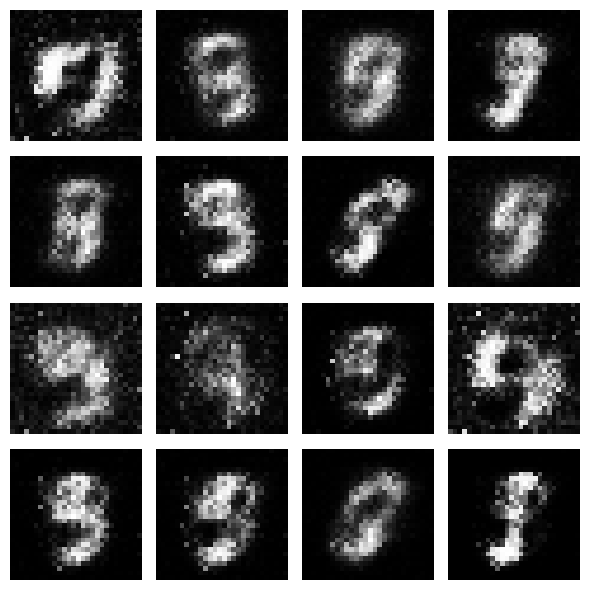

In [26]:
import matplotlib.pyplot as plt
import numpy as np

noise = tf.random.normal([16, 100])

generated_images = generator(noise, training=False)

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap='gray'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

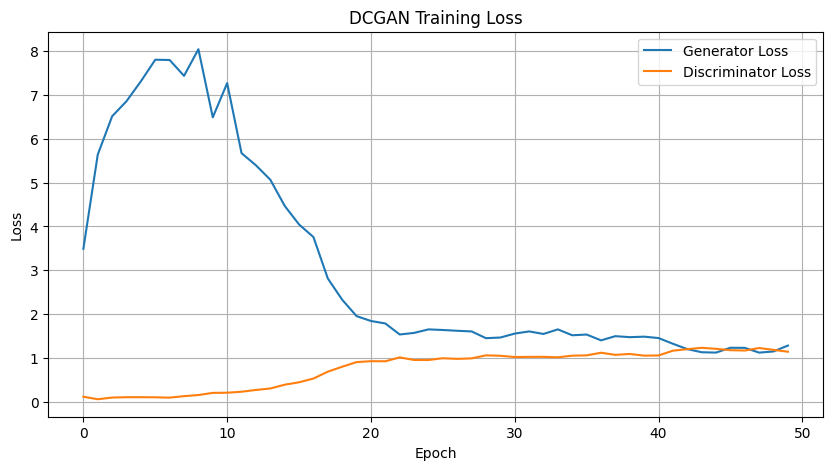

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(generator_losses, label='Generator Loss')
plt.plot(discriminator_losses, label='Discriminator Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DCGAN Training Loss')
plt.legend()
plt.grid(True)
plt.show()